# Tiedonkäsittely Pythonilla (4 op)
### Tekijä: Roni Pihajoki
Lisätään tarvittavat kirjastot & datasetti käyttöön

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('WorkPlaceSatisfactionSurveyData.csv', encoding='utf-8')

## Miltä datasetti näyttää, mitä se pitää sisällään & montako riviä/saraketta siinä on
Ensin on tuloste rivien & sarakkeiden määristä <br>
Sen jälkeen on tuloste taulukon kolmesta ensimmäisestä rivistä <br>
Tästä näemme sarakeotsikot & esimerkit arvoista, joita taulukko sisältää <br>
Tämän pohjalta saamme ajatuksen, mitä dataa meillä on & mitä kaikkea voimme sillä tehdä <br>


In [76]:
print("Rivien lukumäärä: ",df.shape[0])
print("Sarakkeiden lukumäärä: ",df.shape[1])
df.head(3)

Rivien lukumäärä:  82
Sarakkeiden lukumäärä:  16


,number,gender,age,family,education,years_of_service,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks,holidayCabin,gym,muscleCare,healtcare
0,1,1,38,1,1.0,22.0,3587,3,3.0,3,3,3,NaN,NaN,NaN,NaN
1,2,1,29,2,2.0,10.0,2963,1,5.0,2,1,3,NaN,NaN,NaN,NaN
2,3,1,30,1,1.0,7.0,1989,3,4.0,1,1,3,NaN,NaN,NaN,1.0


# Datan käsittely
## Projektin esittely
Minulle tuli seuraavat taustamuuttujat käsiteltäväksi:
- Education (Sarake E) = Luokkamuuttuja
- Salary (Sarake G) = Numeerinen muuttuja

Sat_sarakkeet ovat "tyytyväisyys" sarakkeita<br>
- sat_management = Tämä kertoo kuinka tyytyväisiä johdosta ollaan
- sat_colleques = Tämä kertoo kuinka tyytyväisiä kolleegoista ollaan
- sat_workingEnvironment = Tämä kertoo kuinka tyytyväisiä työympäristöön ollaan
- sat_salary = Tämä kertoo kuinka tyytyväisiä palkkaan ollaan
- sat_tasks = Tämä kertoo kuinka tyytyväisiä työtehtäviin ollaan

Projektissa on ideana että käsitellään ensin jokainen taustamuuttuja & sat_muuttuja erikseen<br>
(esimerkiksi palkan keskiarvo, korkein palkka tai matalin palkka)<br>
Kun yksittäis analysointi on valmista, alamme tutkimaan taustamuuttujia & sat_muuttujia yhdessä<br>
(esimerkiksi miten korkeimman palkan saaja kokee tyytyväisyytensä työympäristöön)<br>
Yhteensä tehdään siis 10 yhdistelmä analysointia & 7 erillistä muuttuja kohtaista analysointia<br>

## Muuttujien arvojen selvennys
Education (Korkein suoritettu tutkinto):
- 1 = peruskoulu tutkinto
- 2 = toisen asteen tutkinto
- 3 = Kandidaatin tutkinto
- 4 = Maisterin tutkinto

Salary:
- Kuukauden palkka euroina

sat_muuttujat:
- Asteikolla 1-5
- 1 tarkoittaa erittäin tyytymätöntä
- 5 tarkoittaa erittäin tyytyväistä

## Taulukon siistiminen
Poistetaan taulukosta meille turhat sarakkeet käyttäen .drop komentoa<br>
1. Tulostetaan tämän hetkisten sarakkeiden nimet
2. Poistetaan sieltä 4 viimeistä saraketta, joita me emme käytä analyysissämme
3. Tulostetaan 3 ensimmäistä riviä uudestaan, josta näemme että sarakkeet on poistettu oikein

In [77]:
df.columns

Index(['number', 'gender', 'age', 'family', 'education', 'years_of_service',
       'salary', 'sat_management', 'sat_colleques', 'sat_workingEnvironment',
       'sat_salary', 'sat_tasks', 'holidayCabin', 'gym', 'muscleCare',
       'healtcare'],
      dtype='str')

In [51]:
df_roni = df.drop(columns=['holidayCabin', 'gym', 'muscleCare', 'healtcare'])



In [52]:
df_roni.head(3)

,number,gender,age,family,education,years_of_service,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks
0,1,1,38,1,1.0,22.0,3587,3,3.0,3,3,3
1,2,1,29,2,2.0,10.0,2963,1,5.0,2,1,3
2,3,1,30,1,1.0,7.0,1989,3,4.0,1,1,3


### Poistetaan myös minulle turhat sarakkeet, joita en käytä omassa analyysissani

In [53]:
df_roni = df_roni.drop(columns=['number', 'gender', 'age', 'family', 'years_of_service'])
df_roni.head(3)

,education,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks
0,1.0,3587,3,3.0,3,3,3
1,2.0,2963,1,5.0,2,1,3
2,1.0,1989,3,4.0,1,1,3


### Tarkastellaan vielä tietoja taulukosta, kuten keskiarvoja, minimeitä ja maksimeita.

In [86]:
df_roni.info()

<class 'pandas.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   education               81 non-null     float64
 1   salary                  82 non-null     int64  
 2   sat_management          82 non-null     int64  
 3   sat_colleques           81 non-null     float64
 4   sat_workingEnvironment  82 non-null     int64  
 5   sat_salary              82 non-null     int64  
 6   sat_tasks               82 non-null     int64  
dtypes: float64(2), int64(5)
memory usage: 4.6 KB


In [82]:
df_roni.describe()

,education,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks
count,81.000000,82.000000,82.000000,81.000000,82.000000,82.000000,82.000000
mean,1.987654,2563.878049,3.060976,4.061728,3.219512,2.109756,3.195122
std,0.844006,849.350302,1.058155,0.826826,1.154961,1.111179,1.047502
min,1.000000,1521.000000,1.000000,2.000000,1.000000,1.000000,1.000000
25%,1.000000,2027.000000,2.000000,4.000000,3.000000,1.000000,3.000000
50%,2.000000,2320.000000,3.000000,4.000000,3.000000,2.000000,3.000000
75%,3.000000,2808.000000,4.000000,5.000000,4.000000,3.000000,4.000000
max,4.000000,6278.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [87]:
for var in df_roni:
    print(var, df_roni[var].unique())

education [ 1.  2.  3.  4. nan]
salary [3587 2963 1989 2144 2183 1910 2066 2768 2106 2651 2846 2808 3393 2691
 5225 2729 2925 2457 4874 3510 4446 1521 2223 1949 2340 6278 1559 2027
 2300 2534 1872 2261 2417 3119 2574 1715 5069 2495 3470 1598 1638 2612]
sat_management [3 1 2 4 5]
sat_colleques [ 3.  5.  4.  2. nan]
sat_workingEnvironment [3 2 1 5 4]
sat_salary [3 1 2 4 5]
sat_tasks [3 2 4 1 5]


### Korjataan puuttuvat arvot sarakkeistani
(Korvaan puuttuvat arvot lukujen keskiarvoilla, jotka olen jo laskenut alhaalla)<br>
Koulutusten keskiarvo on:  2<br>
sat_colleques keskiarvo on: 4<br>

1. tulostetaan tieto tyhjistä arvoista
2. selvitetään rivinumero educationille
3. syötetään riville 29 sarakkeeseen education arvo 2
4. selvitetään rivinumero sat_colleques
3. syötetään riville 56 sarakkeeseen sat_colleques arvo 4


In [54]:
df_roni.isnull().sum()

education                 1
salary                    0
sat_management            0
sat_colleques             1
sat_workingEnvironment    0
sat_salary                0
sat_tasks                 0
dtype: int64

In [ ]:
bool_series = pd.isnull(df_roni["education"])
missing_values_count = bool_series.sum()
filtered_data = df_roni[bool_series]

print("Count of missing values in Education:", missing_values_count)
print(filtered_data)

Count of missing values in Education: 1
    education  salary  sat_management  sat_colleques  sat_workingEnvironment  \
29        NaN    1949               4            4.0                       3   

    sat_salary  sat_tasks  
29           3          2  


In [56]:
bool_series = pd.isnull(df_roni["sat_colleques"])
missing_values_count = bool_series.sum()
filtered_data = df_roni[bool_series]

print("Count of missing values in sat_colleques:", missing_values_count)
print(filtered_data)

Count of missing values in sat_colleques: 1
    education  salary  sat_management  sat_colleques  sat_workingEnvironment  \
56        2.0    3119               2            NaN                       2   

    sat_salary  sat_tasks  
56           1          5  


# Taustamuuttujat

### Education Luokkamuuttuja


Mikä on korkein henkilön suorittama tutkinto<br>
- Peruskoulu tutkintoja korkeimpana suorituksena on 27 henkilöllä<br>
- Toisen asteen tutkintoja korkeimpana suorituksena on 30 henkilöllä<br>
- Kanditaatti tason tutkintoja korkeimpana suorituksena on 22 henkilöllä<br>
- Maisteri tason tutkintoja koirkaimpana suorituksena on 2 henkilöllä


In [88]:
dfe=pd.crosstab(df_roni['education'], 'Count')

dfe

col_0,Count
education,
1.0,27
2.0,30
3.0,22
4.0,2


In [89]:
dfe.index=['Peruskoulu tutkinto', 'Toisen asteen tutkinto', 'Kanditaatti tason tutkinto', 'Maisteri tason tutkinto']
dfe

col_0,Count
Peruskoulu tutkinto,27
Toisen asteen tutkinto,30
Kanditaatti tason tutkinto,22
Maisteri tason tutkinto,2


Koulutusten keskiarvo sekä mediaani ovat 2 (tai ainakin hyvin lähellä 0.0123 erolla)<br>
Poikkkeama normaaliarvosta on 0.84<br>
Varianssin hajonta keskiarvosta 2 on 0.71<br>

In [58]:
e_keskiarvo = df_roni['education'].mean()
e_mediaani = df_roni['education'].median()
e_poikkeama = df_roni['education'].std()
e_varianssi = df_roni['education'].var()

print("Koulutusten keskiarvo on  {:.4f}".format(e_keskiarvo))
print("Koulutusten mediaani on  {:.0f}".format(e_mediaani))
print("Koulutusten poikkeama on  {:.2f}".format(e_poikkeama))
print("Koulutusten varianssi on  {:.2f}".format(e_varianssi))

Koulutusten keskiarvo on  1.9877
Koulutusten mediaani on  2
Koulutusten poikkeama on  0.84
Koulutusten varianssi on  0.71


Text(0.5, 0, 'Korkein suoritettu tutkinto, n=81')

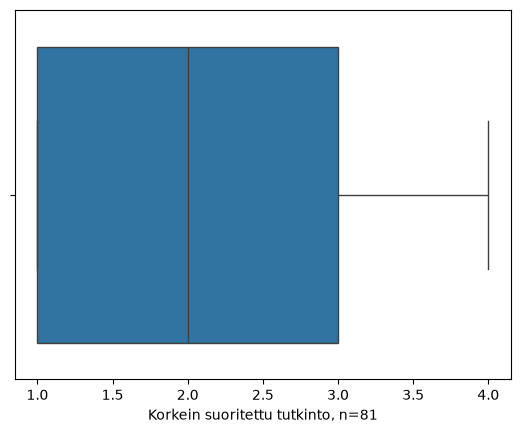

In [85]:
ax3 = sns.boxplot(x = df_roni['education'])

ax3.set_xlabel('Korkein suoritettu tutkinto, n=' + str(df_roni['education'].count()))

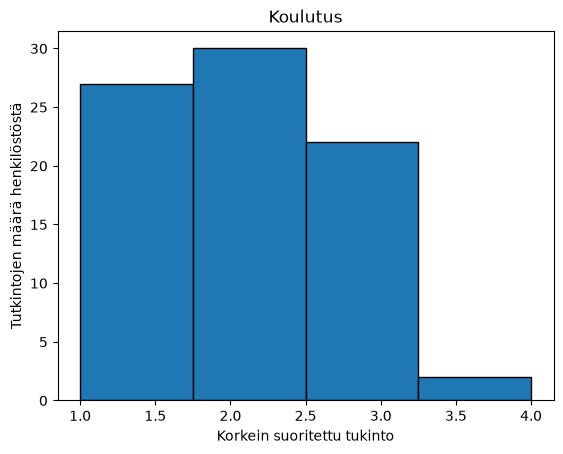

In [59]:
data = df_roni['education']
plt.hist(data, bins=4, density=0, edgecolor='black')
plt.xlabel('Korkein suoritettu tukinto')
plt.ylabel('Tutkintojen määrä henkilöstöstä')
plt.title('Koulutus')
plt.show()

### Salary numeerinen muttuja

In [60]:
s_minimi = df_roni['salary'].min()
s_maximi = df_roni['salary'].max()
s_keskiarvo = df_roni['salary'].mean()
s_mediaani = df_roni['salary'].median()
s_poikkeama = df_roni['salary'].std()

print("Korkein palkka on {:.0f}".format(s_maximi))
print("Matalin palkka on {:.0f}".format(s_minimi))
print(" ")
print("Palkan keskiarvo on  {:.2f}".format(s_keskiarvo))
print("Palkan mediaani on  {:.0f}".format(s_mediaani))
print("Palkan poikkeama on  {:.2f}".format(s_poikkeama))

Korkein palkka on 6278
Matalin palkka on 1521
 
Palkan keskiarvo on  2563.88
Palkan mediaani on  2320
Palkan poikkeama on  849.35


# Sat_Muuttujat

### sat_management

### sat_colleques

In [61]:
s_c_keskiarvo = df_roni['sat_colleques'].mean()
print("Kolleekoiden keskiarvo on  {:.2f}".format(s_c_keskiarvo))

Kolleekoiden keskiarvo on  4.06


### sat_workingEnvironment

### sat_salary

### sat_tasks


# Taustamuuttujien & Sat_muuttujien ristiin vertailu